In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd;
import yaml

import numcosmo_II as nc

from datetime import datetime
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, ScalarFormatter
from pathlib import Path

## Initial Configurations

In [2]:
current_dir  = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'analysis' else current_dir
yaml_path = project_root / 'config' / "setup.yaml"

print( 100 * "=" )
print( "Loading Initial Setup" )
print( f"Project root set as: {project_root}" )
print( 100 * "=" + "\n" )

with open(yaml_path, "r", encoding = "utf-8" ) as config_file:
    config = yaml.safe_load( config_file )

print(f"{yaml.dump( config, sort_keys = False, allow_unicode = True ) }")

config_out   = config[ "output" ]
output_dir   = project_root / config_out["root"]
os.makedirs(output_dir, exist_ok=True)

timestamp     = datetime.now().strftime( "%Y%m%d_%H%M%S" )
base_filename = f"{config_out[ 'base_name' ]}_{timestamp}"
output_base   = output_dir / base_filename

Loading Initial Setup
Project root set as: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II

cosmology:
  h: 0.6737
  Omega_b: 0.0493
  Omega_cdm: 0.2657
  Omega_m: 0.315
  Omega_r: 0.0
  Omega_lambda: 0.685
  w0_fld: -1.0
  wa_fld: 0.0
primordial:
  A_s: 2.1e-09
  n_s: 0.9649
  k_pivot: 0.05
growth:
  a_i: 0.0001
  a_f: 1.0
  num_points: 400
  solver:
    rtol: 1.0e-08
    atol: 1.0e-10
spt:
  box_size_L: 500.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  pk_num_bins: 20
  bispectrum_num_bins: 12
  skewness:
    R_min: 4.0
    R_max: 12.0
    num_radii: 9
ensemble:
  num_realizations: 25
  seed_start: 12345
lpt:
  box_size_L: 200.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  a_ini: 0.01
  a_target: 1.0
  seed: 42
  assignment_scheme: ngp
  pk_num_bins: 25
spherical_collapse:
  ai: 0.0001
  z_c: 0.0
  delta_i: 1e-4
  delta_stop: 1.0e4
  default_model: C
  f_i: 1.0
  n_points: 1000
  shooting:
    delta_i_min: 1.0e-08
    delta_i_max: 0.1
    tol: 1.0e-10
   

In [3]:
# _____ Cosmological Models & Parameters _____ #

cosmo_params = config[ "cosmology" ]
flrw_keys    = [ "h", "Omega_m", "Omega_r", "Omega_lambda", "w0_fld", "wa_fld" ]
flrw_params  = { k: cosmo_params[ k ] for k in flrw_keys if k in cosmo_params }

lcdm_model = nc.FLRW( **flrw_params )

eds_params = flrw_params.copy()
eds_params.update( {"Omega_m": 1.0, "Omega_lambda": 0.0, "Omega_r": 0.0} )
eds_model  = nc.FLRW( **eds_params )

ocdm_params = flrw_params.copy()
ocdm_params.update( {"Omega_m": flrw_params[ "Omega_m" ], "Omega_lambda": 0.0, "Omega_r": 0.0} )
ocdm_model  = nc.FLRW( **ocdm_params )

# _____ Primordial Spectrum Configuration _____ #

primordial_cfg = config[ "primordial" ]
A_s            = primordial_cfg[ "A_s" ]
n_s            = primordial_cfg[ "n_s" ]
k_pivot        = primordial_cfg[ "k_pivot" ]

In [4]:
# _____ Linear Growth Parameters _____ #

a_i = config[ "growth" ][ "a_i" ]
a_f = config[ "growth" ][ "a_f" ]

N_span = [ np.log( a_i ), np.log( a_f ) ]
N_eval = np.linspace( N_span[0], N_span[ 1 ], config[ "growth" ][ "num_points" ] )
a_eval = np.exp (N_eval )

growth_solver_opts = config[ "growth" ][ "solver" ]

In [5]:
# _____ Spherical Collapse Configurations _____ #

sc_cfg           = config[ "spherical_collapse" ]
sc_ai            = float( sc_cfg[ "ai" ] )
sc_zc            = float( sc_cfg[ "z_c"] )
sc_delta_i       = float( sc_cfg[ "delta_i" ] )
sc_delta_stop    = float( sc_cfg[ "delta_stop" ] )
sc_default_model = str ( sc_cfg[ "default_model" ] )
sc_fi            = float( sc_cfg[ "f_i" ] )
sc_n_points      = int( sc_cfg[ "n_points" ] )

sc_shooting_opts = sc_cfg[ "shooting" ]
sc_delta_i_min   = float( sc_shooting_opts[ "delta_i_min" ] )
sc_delta_i_max   = float( sc_shooting_opts[ "delta_i_max" ] )
sc_tol           = float( sc_shooting_opts[ "tol" ] )
sc_max_iter      = int(  sc_shooting_opts[ "max_iter" ] )

In [6]:
# _____ Spherical Collapse Cosmology _____ #

sc_lcdm = nc.SphericalCollapse( lcdm_model )
sc_eds  = nc.SphericalCollapse( eds_model )

ct_lcdm = nc.spherical_collapse.CollapseThreshold(
    sc_lcdm, model = sc_default_model, ai = sc_ai, delta_stop = sc_delta_stop, f_i = sc_fi, n_points = sc_n_points,
    delta_i_min = sc_delta_i_min, delta_i_max = sc_delta_i_max, tol = sc_tol, max_iter = sc_max_iter,
    )

ct_eds = nc.spherical_collapse.CollapseThreshold(
    sc_eds, model = sc_default_model, ai = sc_ai, delta_stop = sc_delta_stop, f_i = sc_fi, n_points = sc_n_points,
    delta_i_min = sc_delta_i_min, delta_i_max = sc_delta_i_max, tol = sc_tol, max_iter = sc_max_iter,
    )

## Spherical Collapse (Ex 4)

In [7]:
sol_eds  = eds_model.solve_growth(  N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_lcdm = lcdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_ocdm = ocdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)

D_eds,  f_eds  = eds_model.get_growth_observables(  sol_eds,  N_eval = N_eval )
D_lcdm, f_lcdm = lcdm_model.get_growth_observables( sol_lcdm, N_eval = N_eval )
D_ocdm, f_ocdm = ocdm_model.get_growth_observables( sol_ocdm, N_eval = N_eval )

In [8]:
f_i_exact = f_lcdm[ 0 ]

theta_i = -f_i_exact * sc_delta_i / ( 1.0 + sc_delta_i )
g_i     = 1.0 / sc_delta_i

print( f"Initial Scale Factor (sc_ai):   {sc_ai:.6e} (N_i = {np.log( sc_ai ):.4f})" )
print( f"Initial Overdensity (sc_delta_i):{sc_delta_i:.6e}" )
print( f"Exact Growth Rate f(sc_ai):     {f_i_exact:.6f}" )
print( f"Initial Velocity Div (theta_i): {theta_i:.6e}" )
print( f"Initial Inverse (g_i):          {g_i:.6e}\n" )

Initial Scale Factor (sc_ai):   1.000000e-04 (N_i = -9.2103)
Initial Overdensity (sc_delta_i):1.000000e-04
Exact Growth Rate f(sc_ai):     1.000000
Initial Velocity Div (theta_i): -9.999000e-05
Initial Inverse (g_i):          1.000000e+04



In [9]:
result = sc_lcdm.integrate( 
    ai = sc_ai, af = a_f, delta_i = sc_delta_i, f_i = f_i_exact, n_points = sc_n_points
    )

### Model Equivalence

In [10]:
a_traj = result[ "a" ]
sol_A  = result[ "Model_A" ]
sol_B  = result[ "Model_B" ]
sol_C  = result[ "Model_C" ]

delta_A = sol_A.y[ 0 ]
delta_B = sol_B.y[ 0 ]
g_C     = sol_C.y[ 0 ]
delta_C = 1.0 / g_C  

theta_B = sol_B.y[ 1 ]
theta_C = sol_C.y[ 1 ]

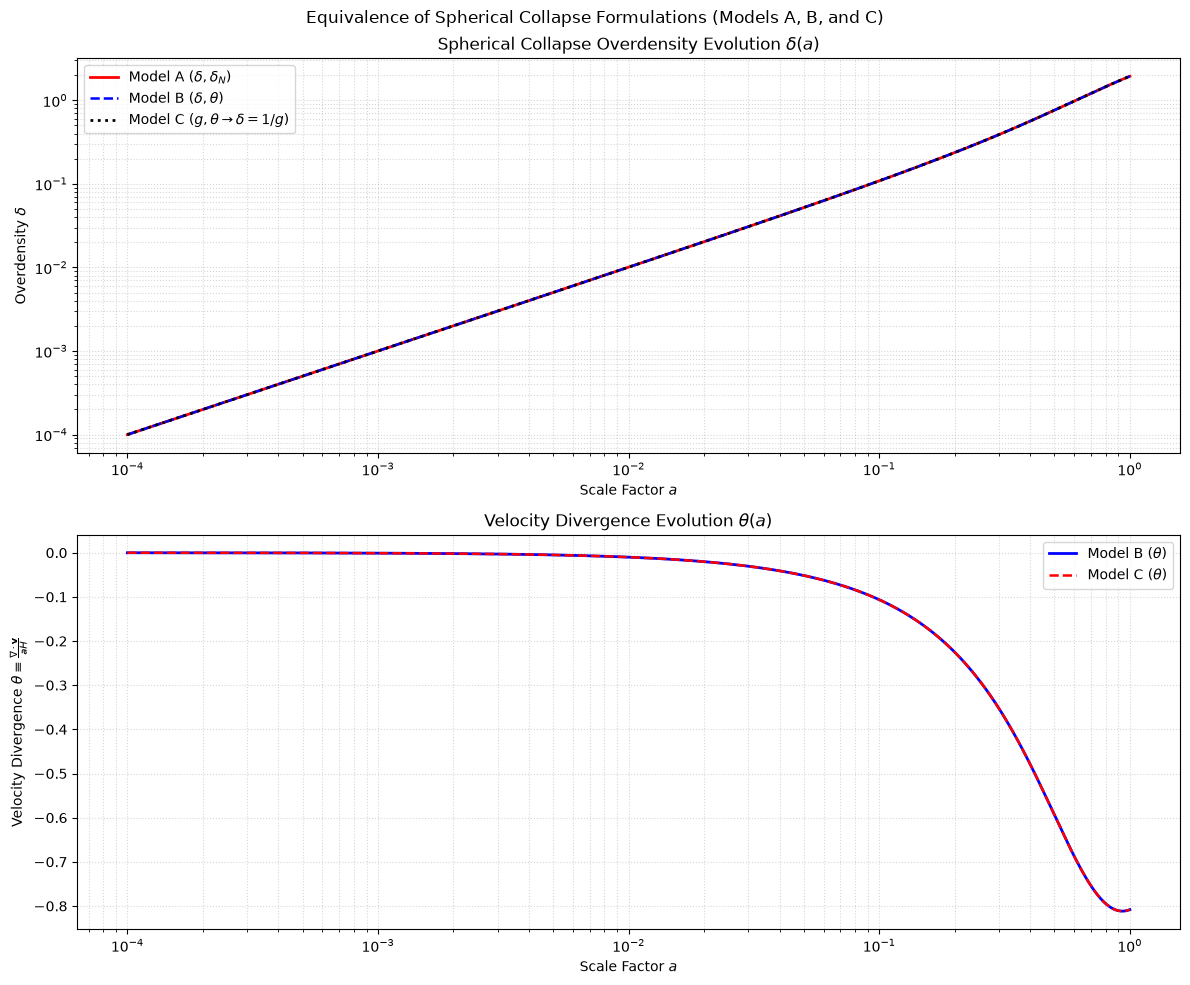

In [11]:
fig, axes = plt.subplots( 2, 1, figsize = ( 12, 10 ) )

axes[ 0 ].plot( a_traj, delta_A, 'r-',  lw = 2.0, label = r"Model A ($\delta, \delta_N$)" )
axes[ 0 ].plot( a_traj, delta_B, 'b--', lw = 1.8, label = r"Model B ($\delta, \theta$)" )
axes[ 0 ].plot( a_traj, delta_C, 'k:',  lw = 2.0, label = r"Model C ($g, \theta \to \delta=1/g$)" )
axes[ 0 ].set_xscale( "log" )
axes[ 0 ].set_yscale( "log" )
axes[ 0 ].set_xlabel( r"Scale Factor $a$" )
axes[ 0 ].set_ylabel( r"Overdensity $\delta$" )
axes[ 0 ].set_title( r"Spherical Collapse Overdensity Evolution $\delta(a)$" )
axes[ 0 ].grid( True, which = "both", ls = ":", alpha = 0.5 )
axes[ 0 ].legend()

axes[ 1 ].plot( a_traj, theta_B, 'b-',  lw = 2.0, label = r"Model B ($\theta$)" )
axes[ 1 ].plot( a_traj, theta_C, 'r--', lw = 1.8, label = r"Model C ($\theta$)" )
axes[ 1 ].set_xscale( "log" )
axes[ 1 ].set_xlabel( r"Scale Factor $a$" )
axes[ 1 ].set_ylabel( r"Velocity Divergence $\theta \equiv \frac{\nabla \cdot \mathbf{v}}{a H}$" )
axes[ 1 ].set_title( r"Velocity Divergence Evolution $\theta(a)$" )
axes[ 1 ].grid( True, which = "both", ls = ":", alpha = 0.5 )
axes[ 1 ].legend()

plt.suptitle( "Equivalence of Spherical Collapse Formulations (Models A, B, and C)", y = 0.98 )
plt.tight_layout()

plot_path_models = f"{output_base}_spherical_collapse_models.png"
plt.savefig( plot_path_models, dpi = 300, bbox_inches = "tight" )
plt.show()

In [12]:
diff_B = np.max( np.abs( ( delta_B - delta_A ) / delta_A ) )
diff_C = np.max( np.abs( ( delta_C - delta_A ) / delta_A ) )

print( 100 * "-" )
print( f"{'Model':<12} | {'delta(a_i)':<18} | {'delta(a_f)':<18} | {'Max Rel Diff vs Model A':<28}" )
print( 100 * "-" )
print( f"{'Model A':<12} | {delta_A[ 0 ]:<18.6e} | {delta_A[ -1 ]:<18.6e} | {'0.0 (Reference)':<28}" )
print( f"{'Model B':<12} | {delta_B[ 0 ]:<18.6e} | {delta_B[ -1 ]:<18.6e} | {diff_B:<28.4e}" )
print( f"{'Model C':<12} | {delta_C[ 0 ]:<18.6e} | {delta_C[ -1 ]:<18.6e} | {diff_C:<28.4e}" )
print( 100 * "-" + "\n" )

----------------------------------------------------------------------------------------------------
Model        | delta(a_i)         | delta(a_f)         | Max Rel Diff vs Model A     
----------------------------------------------------------------------------------------------------
Model A      | 1.000000e-04       | 1.939895e+00       | 0.0 (Reference)             
Model B      | 1.000000e-04       | 1.939895e+00       | 5.5159e-09                  
Model C      | 1.000000e-04       | 1.939894e+00       | 5.7892e-07                  
----------------------------------------------------------------------------------------------------



### Cosmological Grid

In [13]:
grid_models = ["A", "B", "C"]
grid_redshifts = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
grid_Omega_m0_values = [0.2, cosmo_params[ "Omega_m" ], 0.4]
grid_results = []

In [14]:
def growth_rate(cosmology: nc.FLRW, growth_sol, ai: float) -> float:
        """Aux Function."""
        _, f_i = cosmology.get_growth_observables(
            growth_sol,
            N_eval=np.array([np.log(ai)]),
        )
        return float(f_i[0])

In [15]:
for Omega_m0 in grid_Omega_m0_values:
    cosmo_grid_params = flrw_params.copy()
    cosmo_grid_params.update(
        {"Omega_m": Omega_m0, "Omega_lambda": 1.0 - Omega_m0}
    )
    cosmo_grid = nc.FLRW( **cosmo_grid_params )

    a_grid_span = np.geomspace( sc_ai, 1.0, 2000 )
    N_grid_span = np.log( a_grid_span )

    growth_sol_grid = cosmo_grid.solve_growth(
        N  = [ N_grid_span[ 0 ], N_grid_span[ - 1 ] ],
        y0 = [ sc_ai, sc_ai ],
        **growth_solver_opts,
    )

    if not growth_sol_grid.success:
        raise RuntimeError(
            f"Failed to solve for Omega_m0 = {Omega_m0}"
        )
    f_i_grid = growth_rate(cosmo_grid, growth_sol_grid, sc_ai)
    sc_grid  = nc.SphericalCollapse( cosmology = cosmo_grid )

    for model_name in grid_models:
        for z_c in grid_redshifts:

            threshold = nc.spherical_collapse.CollapseThreshold(
                sc_grid,
                model       = model_name,
                ai          = sc_ai,
                delta_stop  = sc_delta_stop,
                f_i         = f_i_grid,
                n_points    = sc_n_points,
                delta_i_min = sc_delta_i_min,
                delta_i_max = sc_delta_i_max,
                tol         = sc_tol,
                max_iter    = sc_max_iter,
            )

            
            delta_i_val, delta_c_val = threshold.find( z_c )

            vir_diag = threshold.virial_overdensity( delta_i_val, z_c )

            a_ta    = vir_diag[ "a_ta" ]
            zeta_ta = vir_diag[ "zeta_ta" ]
            lam_ta  = threshold.lambda_ta_background( Omega_m0, a_ta, zeta_ta )
            y_root  = threshold.physical_virial_root( lam_ta )

            grid_results.append(
                {
                    "Omega_m0":    Omega_m0,
                    "Model":       model_name,
                    "z_c":         z_c,
                    "delta_i":     delta_i_val,
                    "delta_c":     delta_c_val,
                    "Delta_vir_m": vir_diag[ "Delta_vir_m" ],
                    "Delta_vir_c": vir_diag[ "Delta_vir_c" ],
                    "a_ta":        a_ta,
                    "zeta_ta":     zeta_ta,
                    "lambda_ta":   lam_ta,
                    "y_vir":       vir_diag["y_vir"],
                    "y_root_poly": y_root,
                }
            )

grid_df = pd.DataFrame(grid_results)

In [16]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(100 * "-")
print(grid_df.to_string(index=False))
print(100 * "-" + "\n")

csv_output_path = f"{output_base}_spherical_collapse_grid.csv"
grid_df.to_csv(csv_output_path, index=False)
print(f"Results save suscessfully at: {csv_output_path}")

----------------------------------------------------------------------------------------------------
 Omega_m0 Model  z_c  delta_i  delta_c  Delta_vir_m  Delta_vir_c     a_ta  zeta_ta  lambda_ta    y_vir  y_root_poly
    0.200     A  0.0 0.000235 1.661161   430.487587    86.097517 0.542741 7.511855   0.085131 0.477899     0.477899
    0.200     A  0.5 0.000292 1.668735   259.494945   118.751924 0.394393 6.325591   0.038792 0.490122     0.490122
    0.200     A  1.0 0.000361 1.672151   212.034794   141.356529 0.306348 5.918510   0.019431 0.495096     0.495096
    0.200     A  1.5 0.000437 1.673801   193.960830   154.427412 0.248930 5.749464   0.010732 0.497303     0.497303
    0.200     A  2.0 0.000515 1.674700   185.697057   161.736146 0.209034 5.669070   0.006445 0.498384     0.498384
    0.200     A  2.5 0.000596 1.675258   181.418091   165.937081 0.179909 5.626609   0.004140 0.498963     0.498963
    0.200     A  3.0 0.000678 1.675649   178.991464   168.462554 0.157794 5.602264   0.

In [17]:
delta_c_eds_exact   = 1.68647
Delta_vir_eds_exact = 18.0 * np.pi**2

plot_specs = [
    ( "delta_c",     r"$\delta_c(z_c)$",               delta_c_eds_exact,   r"EdS: $\delta_c \approx 1.6865$" ),
    ( "Delta_vir_m", r"$\Delta_{\mathrm{vir,m}}(z_c)$", Delta_vir_eds_exact, r"EdS: $\Delta_{\mathrm{vir}}=18\pi^2$" ),
    ( "Delta_vir_c", r"$\Delta_{\mathrm{vir,c}}(z_c)$", Delta_vir_eds_exact, r"EdS: $\Delta_{\mathrm{vir}}=18\pi^2$" ),
]

model_colors  = { "A": "tab:blue", "B": "tab:orange", "C": "tab:green" }
model_markers = { "A": "o",        "B": "s",          "C": "^" }
omega_styles  = { 0.2: "-", 0.315: "--", 0.4: ":" }

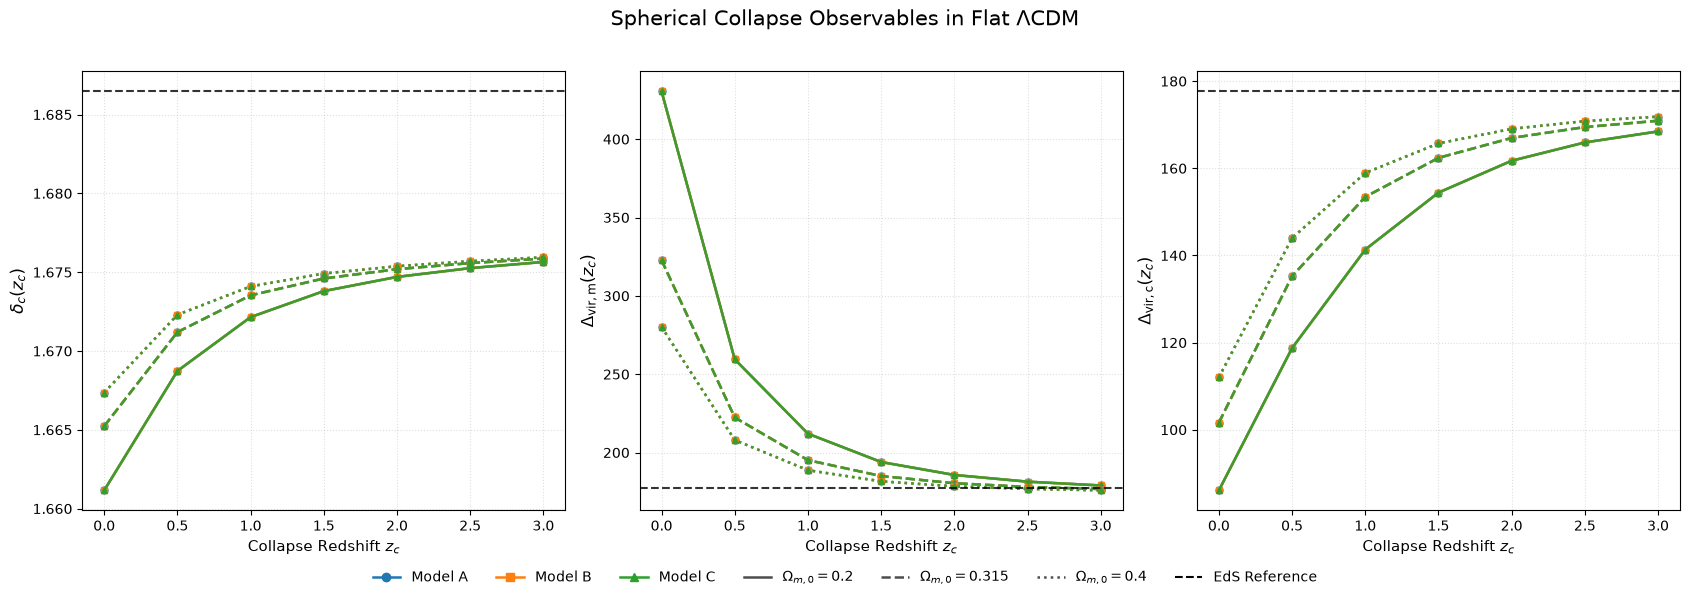

In [18]:
fig, axes = plt.subplots( 1, 3, figsize = ( 17, 5.5 ), sharex = True )

for ax, ( column, ylabel, baseline, baseline_label ) in zip( axes, plot_specs ):
    for Omega_m0 in grid_Omega_m0_values:
        for model in grid_models:
            subset = grid_df[
                np.isclose( grid_df[ "Omega_m0" ], Omega_m0 ) & ( grid_df[ "Model" ] == model )
            ].sort_values( "z_c" )

            if subset.empty:
                continue

            ax.plot(
                subset[ "z_c" ],
                subset[ column ],
                color     = model_colors[ model ],
                linestyle = omega_styles.get( Omega_m0, "-" ),
                marker    = model_markers[ model ],
                ms        = 5,
                lw        = 1.8,
                alpha     = 0.9,
            )

    ax.axhline( baseline, color = "black", linestyle = "--", lw = 1.5, alpha = 0.8 )
    ax.set_xlabel( r"Collapse Redshift $z_c$", fontsize = 11 )
    ax.set_ylabel( ylabel, fontsize = 12 )
    ax.set_xticks( sorted( grid_redshifts ) )
    ax.grid( True, linestyle = ":", alpha = 0.4 )

model_handles = [
    Line2D( [0], [0], color = model_colors[ m ], marker = model_markers[ m ], linestyle = "-", lw = 1.8, label = f"Model {m}" )
    for m in grid_models
]
omega_handles = [
    Line2D( [0], [0], color = "0.3", linestyle = omega_styles.get( v, "-" ), lw = 1.8, label = rf"$\Omega_{{m,0}}={v:g}$" )
    for v in grid_Omega_m0_values
]
ref_handle = Line2D( [0], [0], color = "black", linestyle = "--", lw = 1.5, label = "EdS Reference" )

fig.legend(
    handles        = model_handles + omega_handles + [ ref_handle ],
    loc            = "lower center",
    ncol           = 7,
    frameon        = False,
    bbox_to_anchor = ( 0.5, -0.05 ),
)

fig.suptitle( r"Spherical Collapse Observables in Flat $\Lambda\mathrm{CDM}$", fontsize = 15, y = 1.02 )
plt.tight_layout()

plot_path_grid = f"{output_base}_grid_observables.png"
plt.savefig( plot_path_grid, dpi = 300, bbox_inches = "tight" )
plt.show()

In [19]:
# _____ Independent Audit of Virial Observables & Polynomial Residuals _____ #

audit = grid_df.copy()
audit[ "a_c" ] = 1.0 / ( 1.0 + audit[ "z_c" ] )
audit[ "Delta_vir_m_recomputed" ] = audit[ "zeta_ta" ] * ( audit[ "a_c" ] / audit[ "a_ta" ] )**3 / audit[ "y_vir" ]**3

audit[ "Omega_m_ac" ] = audit.apply(
    lambda r: r[ "Omega_m0" ] / ( r[ "Omega_m0" ] + ( 1.0 - r[ "Omega_m0" ] ) * r[ "a_c" ]**3 ), axis = 1
)
audit[ "Delta_vir_c_recomputed" ] = audit[ "Omega_m_ac" ] * audit[ "Delta_vir_m_recomputed" ]

audit[ "Delta_m_formula_error" ] = audit[ "Delta_vir_m" ] - audit[ "Delta_vir_m_recomputed" ]
audit[ "Delta_c_formula_error" ] = audit[ "Delta_vir_c" ] - audit[ "Delta_vir_c_recomputed" ]

audit[ "virial_polynomial_residual" ] = (
    4.0 * audit[ "lambda_ta" ] * audit[ "y_vir" ]**3 - 2.0 * ( 1.0 + audit[ "lambda_ta" ] ) * audit[ "y_vir" ] + 1.0
)

audit_summary = pd.DataFrame( [
    {
        "check":            "All grid observables finite",
        "passed":           np.isfinite( audit[ [ "delta_c", "Delta_vir_m", "Delta_vir_c" ] ].to_numpy() ).all(),
        "max_abs_residual": np.nan,
    },
    {
        "check":            "Matter-referenced virial formula",
        "passed":           np.max( np.abs( audit[ "Delta_m_formula_error" ] ) ) <= 1e-6,
        "max_abs_residual": np.max( np.abs( audit[ "Delta_m_formula_error" ] ) ),
    },
    {
        "check":            "Critical-referenced virial formula",
        "passed":           np.max( np.abs( audit[ "Delta_c_formula_error" ] ) ) <= 1e-6,
        "max_abs_residual": np.max( np.abs( audit[ "Delta_c_formula_error" ] ) ),
    },
    {
        "check":            "Virial cubic polynomial residual",
        "passed":           np.max( np.abs( audit[ "virial_polynomial_residual" ] ) ) <= 1e-5,
        "max_abs_residual": np.max( np.abs( audit[ "virial_polynomial_residual" ] ) ),
    },
] )

print( 100 * "=" )
print( "Independent Audit Summary:" )
print( 100 * "=" )
print( audit_summary.to_string( index = False ) )
print( 100 * "=" + "\n" )

Independent Audit Summary:
                             check  passed  max_abs_residual
       All grid observables finite    True               NaN
  Matter-referenced virial formula    True      5.684342e-14
Critical-referenced virial formula    True      8.526513e-14
  Virial cubic polynomial residual    True      5.018208e-14



### Critical Collapse Threshold $\delta_c$ via Shooting Method

In [20]:
print( 100 * "=" )
print( "Calculating Linear Collapse Threshold delta_c via Shooting Method" )
print( 100 * "=" + "\n" )

delta_i_lcdm, delta_c_lcdm = ct_lcdm.find( z_c = sc_zc )
delta_i_eds,  delta_c_eds  = ct_eds.find(  z_c = sc_zc )

delta_c_eds_exact = 1.68647 

print( f"Target Collapse Redshift (z_c): {sc_zc:.2f}\n" )
print( f"Flat LCDM -> Initial delta_i: {delta_i_lcdm:.6e} | Critical delta_c: {delta_c_lcdm:.5f}" )
print( f"Flat EdS  -> Initial delta_i: {delta_i_eds:.6e}  | Critical delta_c: {delta_c_eds:.5f} (Analytical: {delta_c_eds_exact:.5f})" )
print( f"EdS Relative Error: {abs( delta_c_eds - delta_c_eds_exact ) / delta_c_eds_exact:.4e}\n" )


Calculating Linear Collapse Threshold delta_c via Shooting Method

Target Collapse Redshift (z_c): 0.00

Flat LCDM -> Initial delta_i: 2.113745e-04 | Critical delta_c: 1.66524
Flat EdS  -> Initial delta_i: 1.675176e-04  | Critical delta_c: 1.67518 (Analytical: 1.68647)
EdS Relative Error: 6.6967e-03



In [21]:
z_array        = np.linspace( 0.0, 3.0, 20 )
delta_c_lcdm_z = []
delta_c_eds_z  = []

for z in z_array:
    _, dc_l = ct_lcdm.find( z_c = z )
    _, dc_e = ct_eds.find(  z_c = z )
    delta_c_lcdm_z.append( dc_l )
    delta_c_eds_z.append( dc_e )

delta_c_lcdm_z = np.array( delta_c_lcdm_z )
delta_c_eds_z  = np.array( delta_c_eds_z )

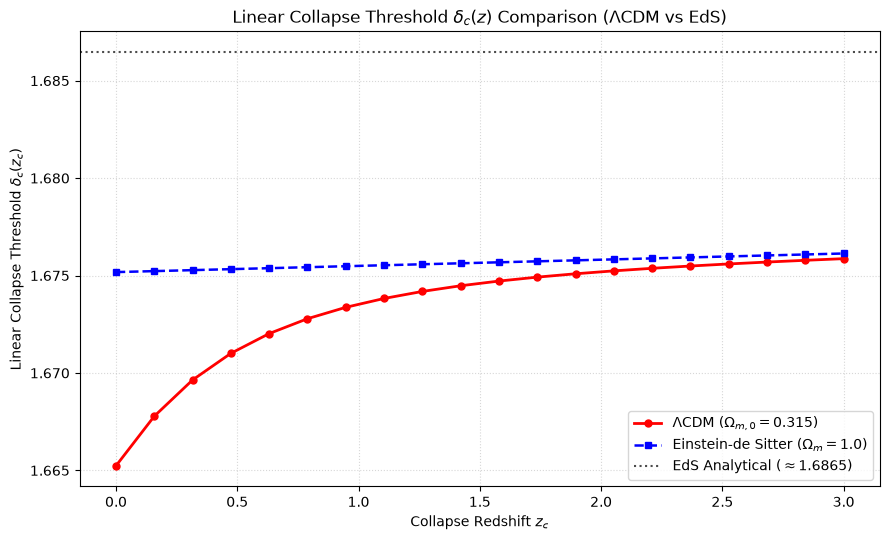

In [22]:
plt.figure( figsize = ( 9, 5.5 ) )
plt.plot( z_array, delta_c_lcdm_z, 'r-o', lw = 2.0, ms = 5, label = r"$\Lambda\mathrm{CDM}$ ($\Omega_{m,0}=0.315$)" )
plt.plot( z_array, delta_c_eds_z,  'b--s', lw = 1.8, ms = 5, label = r"Einstein-de Sitter ($\Omega_m=1.0$)" )
plt.axhline( delta_c_eds_exact, color = 'k', linestyle = ':', alpha = 0.7, label = r"EdS Analytical ($\approx 1.6865$)" )

plt.xlabel( r"Collapse Redshift $z_c$" )
plt.ylabel( r"Linear Collapse Threshold $\delta_c(z_c)$" )
plt.title( r"Linear Collapse Threshold $\delta_c(z)$ Comparison ($\Lambda\mathrm{CDM}$ vs EdS)" )
plt.grid( True, ls = ":", alpha = 0.5 )
plt.legend( )
plt.tight_layout()

plot_path_deltac = f"{output_base}_delta_c_redshift_evolution.png"
plt.savefig( plot_path_deltac, dpi = 300, bbox_inches = "tight" )
plt.show()

### $\delta_c(z_c)$ Validation between Models A, B e C

In [23]:
print( 100 * "=" )
print( "Comparing Linear Collapse Threshold delta_c across Models A, B, and C" )
print( 100 * "=" + "\n" )

models = [ "A", "B", "C" ]
redshifts = [ 0.0, 0.5, 1.0, 2.0, 3.0 ]

results = []

for model in models:
    for z_c in redshifts:

        threshold = nc.spherical_collapse.CollapseThreshold(
            sc_lcdm,
            model       = model,
            ai          = sc_ai,
            delta_stop  = sc_delta_stop,
            f_i         = f_i_exact,
            n_points    = sc_n_points,
            delta_i_min = sc_delta_i_min,
            delta_i_max = sc_delta_i_max,
            tol         = sc_tol,
            max_iter    = sc_max_iter,
        )

        delta_i, delta_c = threshold.find( z_c = z_c )

        results.append( {
            "Model":   model,
            "z_c":     z_c,
            "a_c":     1.0 / ( 1.0 + z_c ),
            "f_i":     f_i_exact,
            "delta_i": delta_i,
            "delta_c": delta_c,
        } )

results_df = pd.DataFrame( results )

Comparing Linear Collapse Threshold delta_c across Models A, B, and C



In [24]:
pivot = results_df.pivot( index = "z_c", columns = "Model", values = "delta_c" )

print( "Linear collapse thresholds delta_c(z_c):" )
print( 100 * "-" )
print( pivot.to_string() )
print( 100 * "-" + "\n" )

Linear collapse thresholds delta_c(z_c):
----------------------------------------------------------------------------------------------------
Model         A         B         C
z_c                                
0.0    1.665235  1.665235  1.665235
0.5    1.671197  1.671197  1.671197
1.0    1.673532  1.673532  1.673532
2.0    1.675192  1.675192  1.675192
3.0    1.675866  1.675866  1.675866
----------------------------------------------------------------------------------------------------



In [25]:
relative_difference = 100.0 * ( pivot.div( pivot[ "A" ], axis = 0 ) - 1.0 )

print( "Relative difference with respect to Model A (%):" )
print( 100 * "-" )
print( relative_difference.to_string() )
print( 100 * "-" + "\n" )

Relative difference with respect to Model A (%):
----------------------------------------------------------------------------------------------------
Model    A             B             C
z_c                                   
0.0    0.0  1.950495e-08  7.874401e-08
0.5    0.0  2.671097e-08  9.118186e-08
1.0    0.0  2.263481e-08  8.981784e-08
2.0    0.0  2.456415e-08  8.952707e-08
3.0    0.0  2.782656e-08  8.805077e-08
----------------------------------------------------------------------------------------------------



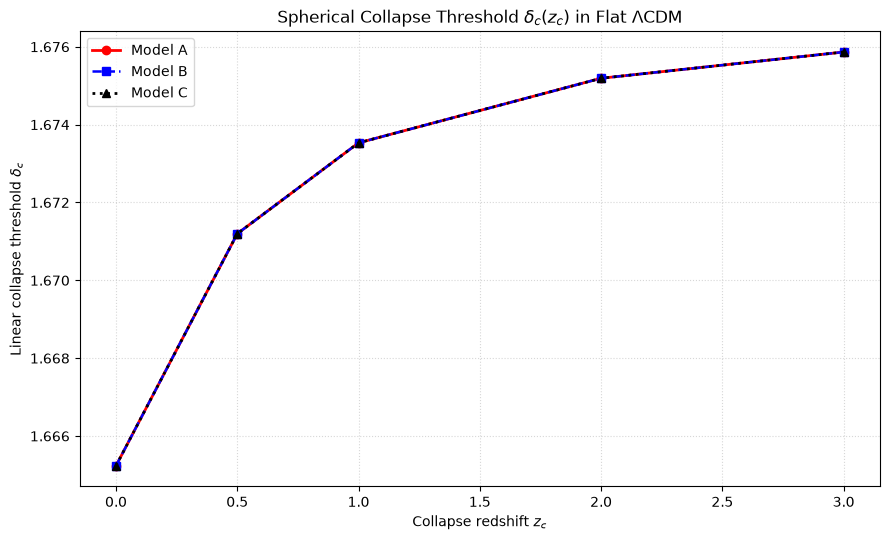

In [26]:
plt.figure( figsize = ( 9, 5.5 ) )

styles = { "A": ( "r-o", 2.0 ), "B": ( "b--s", 1.8 ), "C": ( "k:^", 2.0 ) }

for model in models:
    subset = results_df[ results_df[ "Model" ] == model ]
    fmt, lw = styles[ model ]
    plt.plot(
        subset[ "z_c" ],
        subset[ "delta_c" ],
        fmt,
        lw     = lw,
        ms     = 6,
        label  = f"Model {model}",
    )

plt.xlabel( r"Collapse redshift $z_c$" )
plt.ylabel( r"Linear collapse threshold $\delta_c$" )
plt.title( r"Spherical Collapse Threshold $\delta_c(z_c)$ in Flat $\Lambda\mathrm{CDM}$" )
plt.grid( True, ls = ":", alpha = 0.5 )
plt.legend()
plt.tight_layout()

plot_path_models_zc = f"{output_base}_models_delta_c_comparison.png"
plt.savefig( plot_path_models_zc, dpi = 300, bbox_inches = "tight" )
plt.show()

### Einstein–de Sitter (EdS) Convergence Tests

In [27]:
# _____ Convergence Analysis in Einstein-de Sitter (EdS) Cosmology _____ #

convergence_results = []

a_grid_eds = np.geomspace( 1e-7, 1.0, 3000 )
N_grid_eds = np.log( a_grid_eds )

growth_eds = eds_model.solve_growth(
    N  = [ N_grid_eds[ 0 ], N_grid_eds[ -1 ] ],
    y0 = [ 1e-7, 1e-7 ],
    rtol = 1e-11,
    atol = 1e-13,
)

if not growth_eds.success:
    raise RuntimeError( "Failed to solve linear growth for EdS cosmology." )

sc_eds_conv = nc.SphericalCollapse( cosmology = eds_model )

convergence_cases = []


In [28]:
# Varying ai
for ai_test in [ 1e-3, 1e-4, 1e-5 ]:
    convergence_cases.append( ( "ai", ai_test, ai_test, 1e5, 1e-8, 1e-10 ) )

# Varying Integration Tolerances
for rtol_test, atol_test in [ ( 1e-6, 1e-8 ), ( 1e-8, 1e-10 ), ( 1e-10, 1e-12 ) ]:
    convergence_cases.append( ( "tolerance", rtol_test, 1e-3, 1e5, rtol_test, atol_test ) )

# Varying Singular Threshold delta_stop
for delta_stop_test in [ 1e5, 1e6, 1e7, 1e8 ]:
    convergence_cases.append( ( "delta_stop", delta_stop_test, 1e-3, delta_stop_test, 1e-8, 1e-10 ) )

In [29]:
for model in grid_models:
    for z_c in grid_redshifts:
        for varied_param, setting, ai_test, stop_test, rtol_test, atol_test in convergence_cases:
            f_i_eds = growth_rate( eds_model, growth_eds, ai_test )

            threshold = nc.spherical_collapse.CollapseThreshold(
                collapse    = sc_eds_conv,
                model       = model,
                ai          = ai_test,
                delta_stop  = stop_test,
                f_i         = f_i_eds,
                n_points    = 1500,
                delta_i_min = 1e-10,
                delta_i_max = 1e-2,
                tol         = 1e-10,
                max_iter    = 150,
                rtol        = rtol_test,
                atol        = atol_test,
            )

            delta_i_val, delta_c_val = threshold.find( z_c )
            vir = threshold.virial_overdensity( delta_i_val, z_c )
            a_c = 1.0 / ( 1.0 + z_c )

            convergence_results.append( {
                "Model":               model,
                "z_c":                 z_c,
                "varied_parameter":    varied_param,
                "setting":             setting,
                "ai":                  ai_test,
                "delta_stop":          stop_test,
                "rtol":                rtol_test,
                "atol":                atol_test,
                "delta_i":             delta_i_val,
                "delta_c":             delta_c_val,
                "delta_c_error":       delta_c_val - delta_c_eds_exact,
                "a_ta/a_c":            vir[ "a_ta" ] / a_c,
                "zeta_ta":             vir[ "zeta_ta" ],
                "y_vir":               vir[ "y_vir" ],
                "Delta_vir_m":         vir[ "Delta_vir_m" ],
                "Delta_vir_m_error":   vir[ "Delta_vir_m" ] - Delta_vir_eds_exact,
                "Delta_vir_c":         vir[ "Delta_vir_c" ],
                "Delta_vir_c_error":   vir[ "Delta_vir_c" ] - Delta_vir_eds_exact,
                "turnaround_residual": vir[ "event_residual" ],
                "Omega_m0":            1.0,
                "Omega_Lambda0":       0.0,
            } )

convergence_df = pd.DataFrame( convergence_results )

In [30]:
print( 100 * "=" )
print( "Maximum Absolute Residuals by Model (EdS Convergence):" )
print( 100 * "=" )
print(
    convergence_df.groupby( "Model" )[
        [ "delta_c_error", "Delta_vir_m_error", "Delta_vir_c_error", "turnaround_residual" ]
    ].agg( lambda x: x.abs().max() )
)
print( 100 * "=" + "\n" )

Maximum Absolute Residuals by Model (EdS Convergence):
       delta_c_error  Delta_vir_m_error  Delta_vir_c_error  turnaround_residual
Model                                                                          
A            0.01287           1.139117           1.139117         3.996803e-15
B            0.01287           1.139117           1.139117         3.996803e-15
C            0.01287           1.139117           1.139117         3.996803e-15



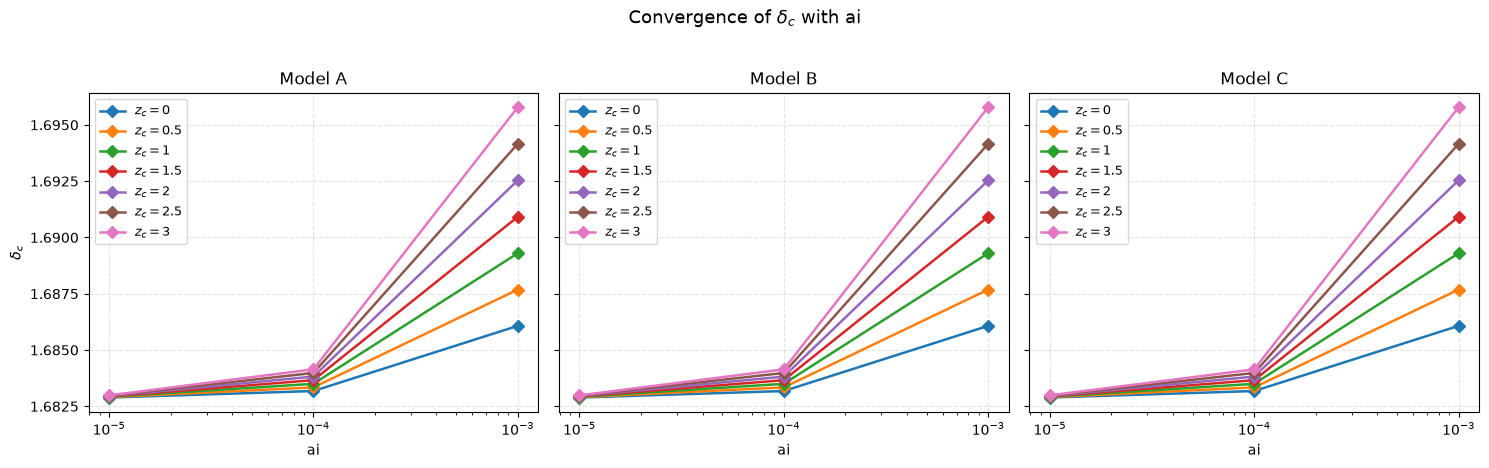

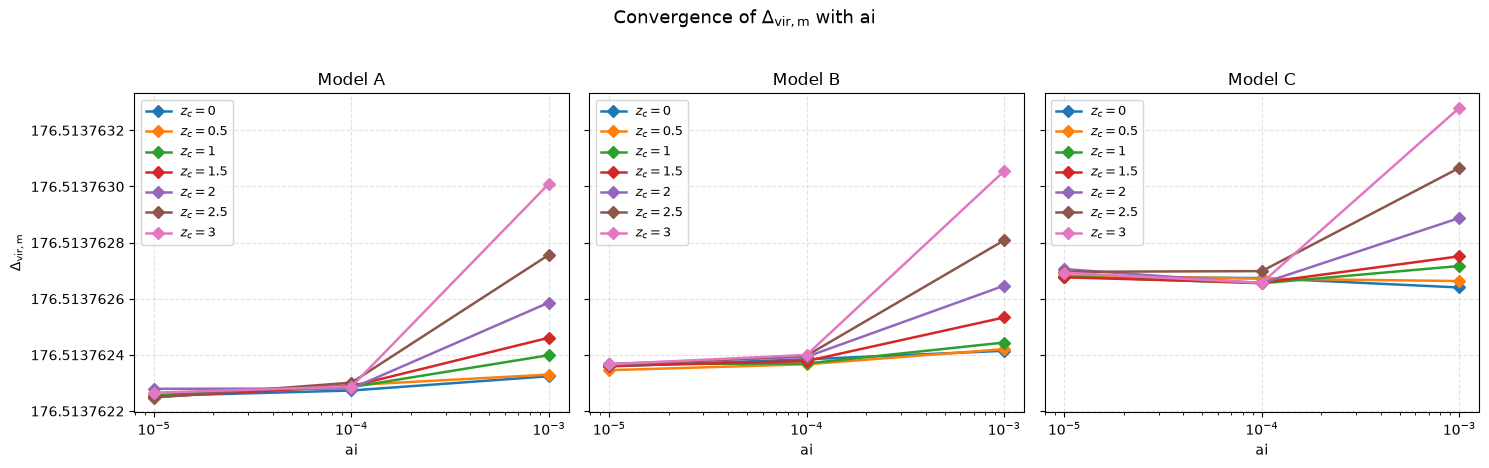

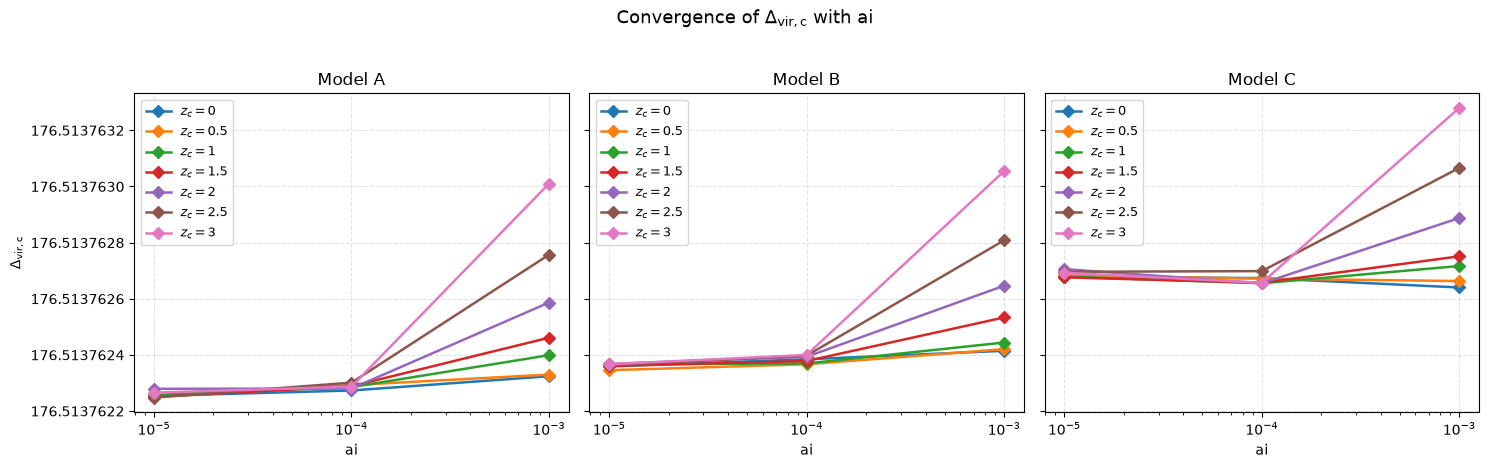

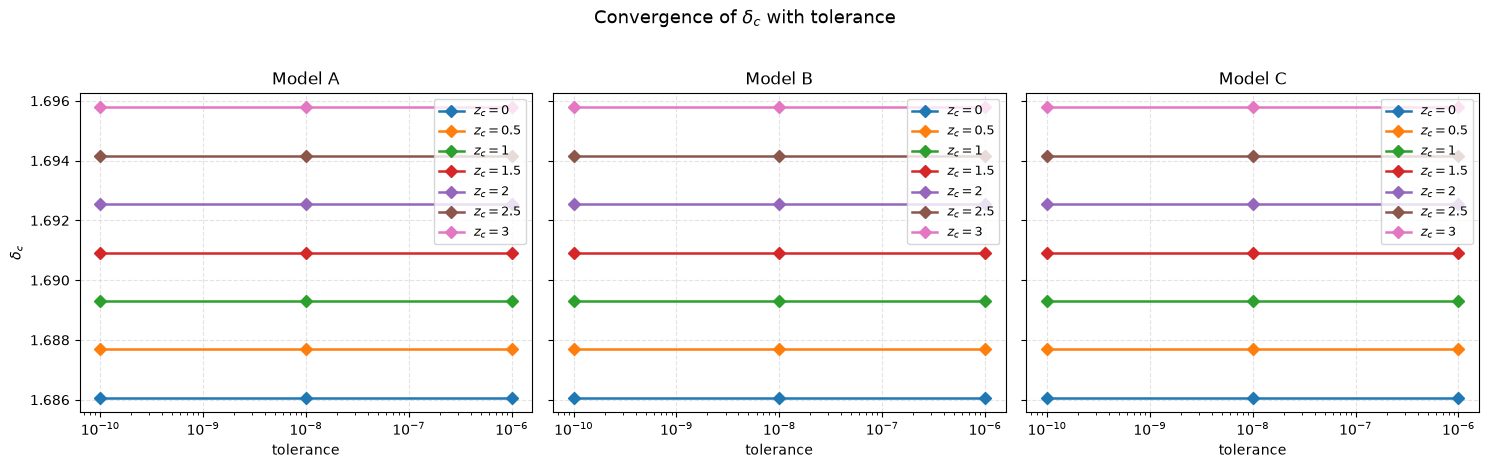

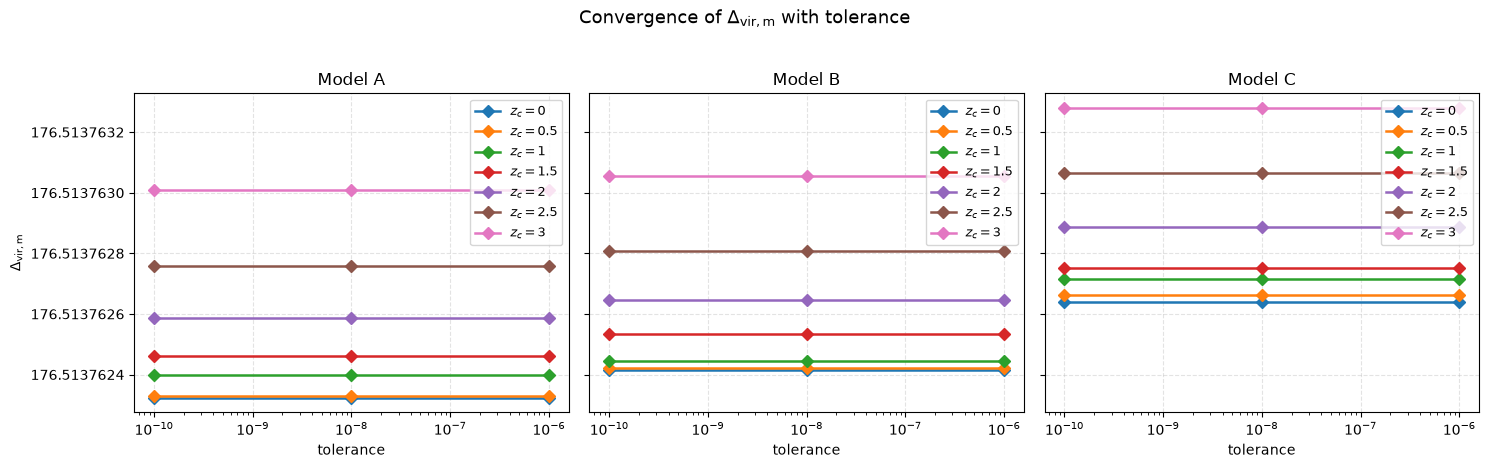

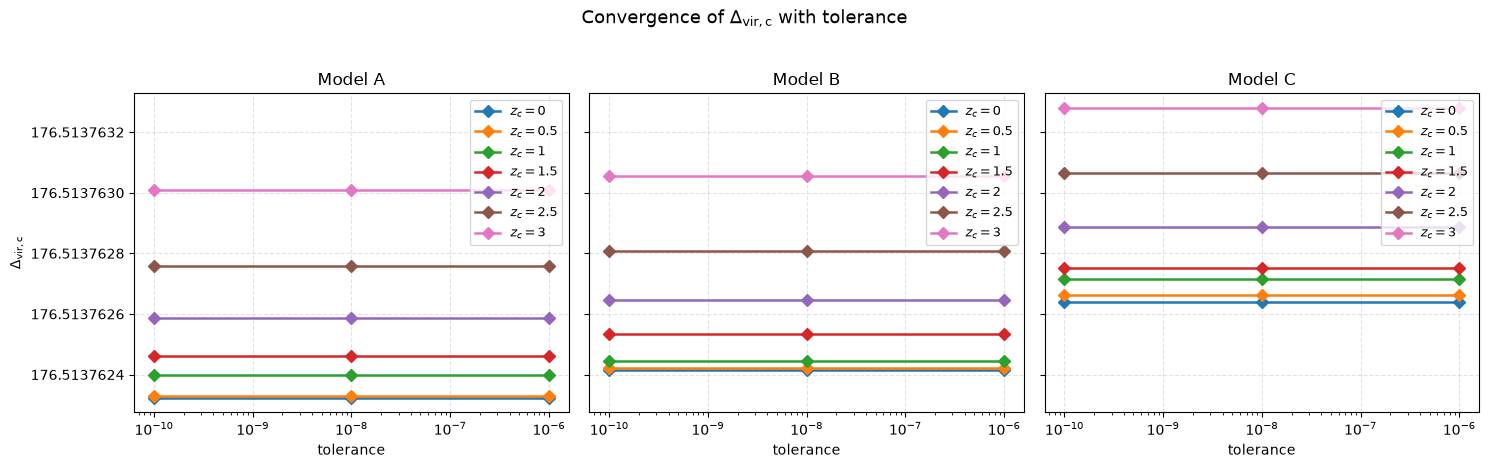

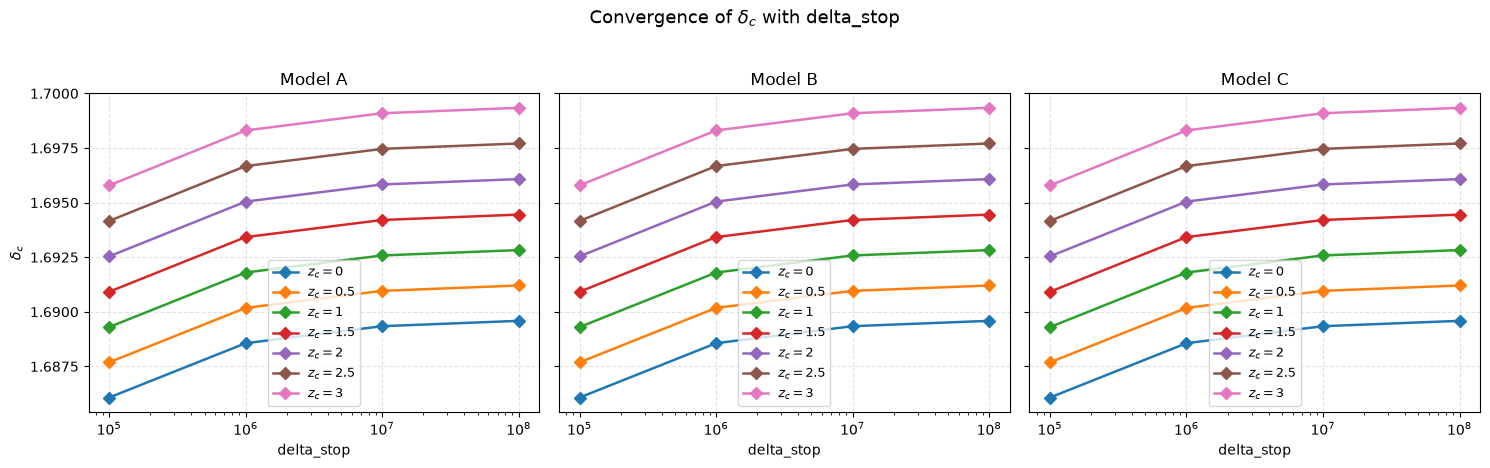

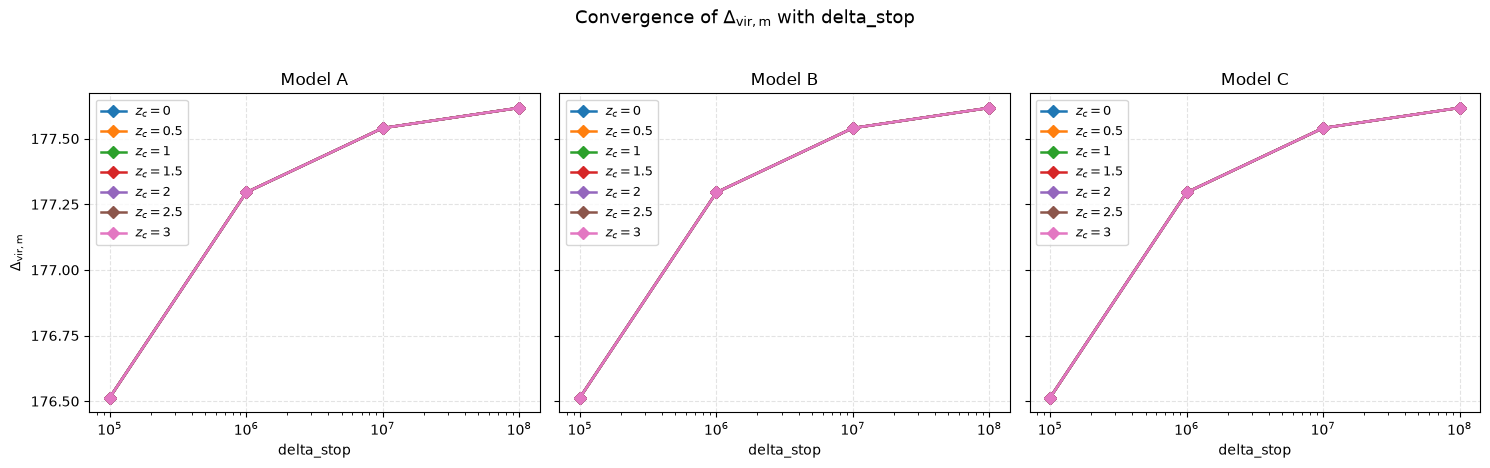

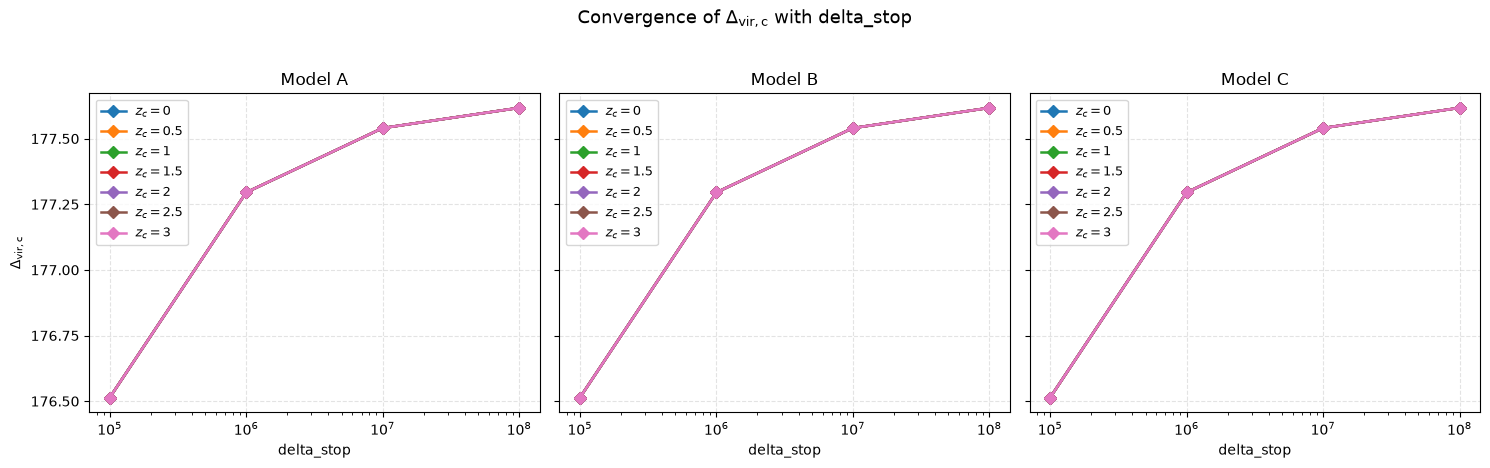

In [31]:
# _____ Convergence Plots Across Numerical Parameters _____ #

marker_dict = { 0.0: "o", 0.5: "v", 1.0: "s", 1.5: "<", 2.0: "^", 2.5: ">", 3.0: "D" }
marker = marker_dict.get( z_c, "o" )

for varied in [ "ai", "tolerance", "delta_stop" ]:
    subset_all = convergence_df[ convergence_df[ "varied_parameter" ] == varied ].copy()

    for observable, ylabel in [
        ( "delta_c",     r"$\delta_c$" ),
        ( "Delta_vir_m", r"$\Delta_{\mathrm{vir,m}}$" ),
        ( "Delta_vir_c", r"$\Delta_{\mathrm{vir,c}}$" ),
    ]:
        fig, axes = plt.subplots( 1, 3, figsize = ( 15, 4.5 ), sharey = True )

        for ax, model in zip( axes, grid_models ):
            model_data = subset_all[ subset_all[ "Model" ] == model ]
            for z_c in grid_redshifts:
                subset = model_data[ model_data[ "z_c" ] == z_c ].sort_values( "setting" )

                if subset.empty:
                    continue

                ax.plot(
                    subset[ "setting" ],
                    subset[ observable ],
                    marker = marker,
                    lw     = 1.8,
                    ms     = 6,
                    label  = fr"$z_c={z_c:g}$",
                )

            ax.set_title( f"Model {model}" )
            ax.set_xlabel( varied )
            ax.grid( True, linestyle = "--", alpha = 0.35 )
            ax.legend( fontsize = 9 )

            if len( model_data ) and ( model_data[ "setting" ] > 0 ).all():
                ax.set_xscale( "log" )

        axes[ 0 ].set_ylabel( ylabel )

        formatter = ScalarFormatter( useOffset = False )
        formatter.set_scientific( False )
        for ax in axes:
            ax.yaxis.set_major_formatter( formatter )
            ax.yaxis.set_major_locator( MaxNLocator( 6 ) )

        fig.suptitle( f"Convergence of {ylabel} with {varied}", fontsize = 13, y = 1.03 )
        plt.tight_layout()

        plot_conv_path = f"{output_base}_convergence_{observable}_{varied}.png"
        plt.savefig( plot_conv_path, dpi = 300, bbox_inches = "tight" )
        plt.show()

In [33]:
# _____ Final Structural & Numerical Validation Checklist _____ #

expected_cases = len( grid_models ) * len( grid_redshifts ) * len( grid_Omega_m0_values )


final_checks = [
    ( "Turnaround & virial observables recorded", all( c in grid_df.columns for c in [ "a_ta", "zeta_ta", "y_vir", "Delta_vir_m", "Delta_vir_c" ] ) ),
    ( "Polynomial virial root comparison recorded", "y_root_polynomial" in grid_df.columns ),
    ( "Independent formula audit passed",           audit_summary[ "passed" ].all() ),
    ( f"Cosmological grid contains {expected_cases} cases", len( grid_df ) == expected_cases ),
    ( "Convergence table generated and finite",     len( convergence_df ) > 0 and np.isfinite( convergence_df[ "turnaround_residual" ].to_numpy() ).all() ),
]

checks_summary_df = pd.DataFrame( final_checks, columns = [ "Validation Check", "Status" ] )

print( 100 * "=" )
print( "Final Spherical Collapse Validation Summary" )
print( 100 * "=" )
print( checks_summary_df.to_string( index = False ) )
print( 100 * "=" + "\n" )

if checks_summary_df[ "Status" ].all():
    print( "All structural and numerical validation checks completed successfully!" )

Final Spherical Collapse Validation Summary
                          Validation Check  Status
  Turnaround & virial observables recorded    True
Polynomial virial root comparison recorded   False
          Independent formula audit passed    True
       Cosmological grid contains 63 cases    True
    Convergence table generated and finite    True

